# 03 - Calibration Notebook

This notebook trains and evaluates the selected Random Forest classifier from the previous notebook on the same dataset that it was run previously.
- Analyzes model performance using accuracy, F1 score, classification report, and confusion matrix
- Plots feature importance from the trained model
- **Uses a multiclass threshold tuning strategy to optimize predictions, specifically minimizing Low→High classification errors**

<h2>Training the Random Forest classifier</h2>

**Model Initialization and Training**

The model is initialized with specific hyperparameters found in the grid search from the previous notebook:
- **`max_depth`**: No more than 12 levels of splits
- **`max_features`**: each tree is limited to a random subset of features, with the number of features in that subset equal to the square root of total features
- **`min_samples_leaf`**: 1 allows individual trees to grow until their leaves contain only a single data point (allowing high complexity). We rely on max_depth to control the overall depth of the tree even when min_samples_leaf would allow for deeper growth
- **`n_estimators`**: 600 trees in the forest

Then the model is trained using the ohe dataset that was saved from the previous notebook, *spotify_clean_tree_ohe.csv*

**Model Evaluation**

Predictions are made and the performance is evaluated using:
- **`accuracy_score`**: Overall proportion of correctly classified songs
- **`F1 score`**: Harmonic mean of precision and recall
- **`classification_report`**: Detailed metrics showing precision, recall, F1 score, and support for each class

**Confusion Matrix**

The confusion matrix is displayed, visualizing the performance of the model in each class. The sum of each row is 100%.

**Feature Importance**

The top 30 most important features are identified and visualized. This helps with understanding which features contributed most to the predictions made by the model.

Accuracy: 0.615909090909091
F1 (macro): 0.6124391598075808

Classification report:
               precision    recall  f1-score   support

           0      0.568     0.652     0.607       115
           1      0.602     0.479     0.533       167
           2      0.663     0.734     0.697       158

    accuracy                          0.616       440
   macro avg      0.611     0.622     0.612       440
weighted avg      0.615     0.616     0.611       440



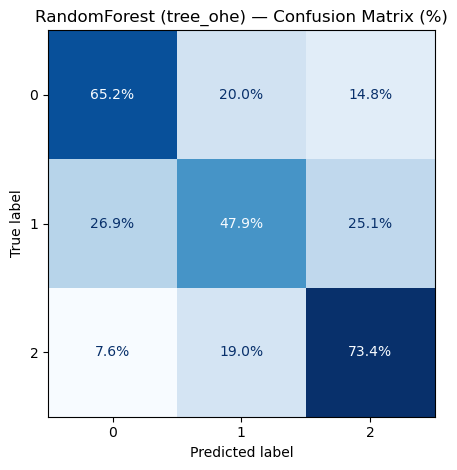

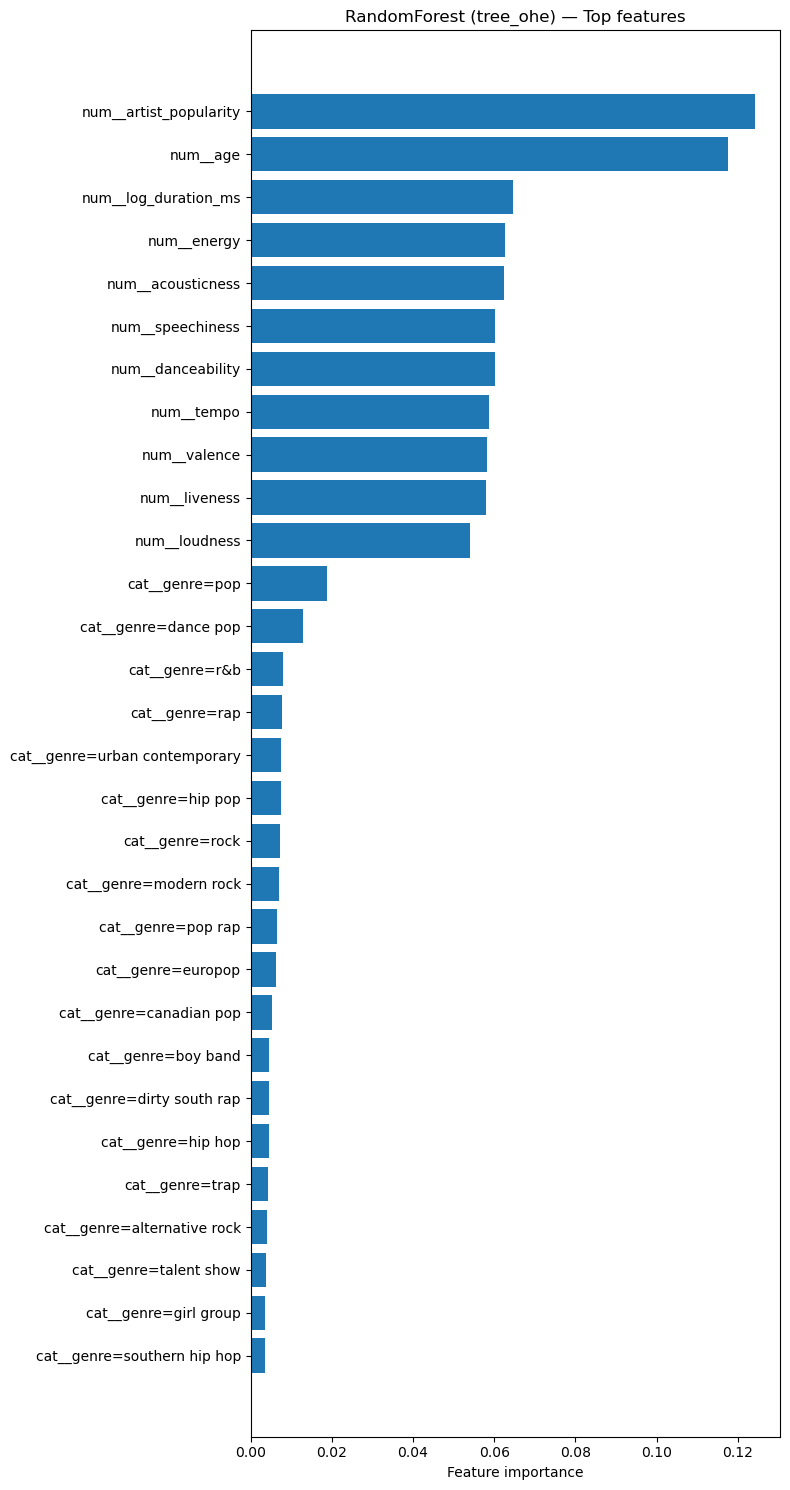

In [1]:
# RandomForest on the preprocessed OHE dataset saved earlier
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

df = pd.read_csv("../data/spotify_clean_tree_ohe.csv")
train = df[df["split"]=="train"].drop(columns=["split"])
test  = df[df["split"]=="test"].drop(columns=["split"])

X_train, y_train = train.drop(columns=["target"]), train["target"].astype(int)
X_test,  y_test  = test.drop(columns=["target"]),  test["target"].astype(int)


# Fit RandomForest with chosen parameters
clf = RandomForestClassifier(
    max_depth=12,
    max_features="sqrt",
    min_samples_leaf=1,
    n_estimators=600,
    random_state=42,
    n_jobs=-1,
)
clf.fit(X_train, y_train)

# Predict and Evaluate
pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))
print("F1 (macro):", f1_score(y_test, pred, average="macro"))
print("\nClassification report:\n", classification_report(y_test, pred, digits=3))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, labels=np.unique(y_test),
    normalize="true", values_format=".1%", cmap="Blues", colorbar=False
)
plt.title("RandomForest (tree_ohe) — Confusion Matrix (%)")
plt.tight_layout()
plt.show()

# Feature importances (top 30)
importances = clf.feature_importances_
feat_names = np.array(X_test.columns)
idx = np.argsort(importances)[::-1]
top_n = min(30, len(idx))

plt.figure(figsize=(8, 0.4 * top_n + 3))
plt.barh(range(top_n), importances[idx[:top_n]][::-1])
plt.yticks(range(top_n), feat_names[idx[:top_n]][::-1])
plt.xlabel("Feature importance")
plt.title("RandomForest (tree_ohe) — Top features")
plt.tight_layout()
plt.show()


**Calculate predicted probabilities for each class**

Previously the class was predicted using `clf.predict(X_test)`

In order to see the probability of belonging to each class, we can use `clf.predict_proba(X_test)`

This returns an array where each row represents a song, and each column represents the probability of belonging to that particular class. This allows for threshold tuning, which is performed in the cell after this.

In [2]:
proba = clf.predict_proba(X_test)
proba[0:3] # show first 3 as an example

array([[0.26646607, 0.32452276, 0.40901117],
       [0.12320882, 0.3563362 , 0.52045499],
       [0.69758111, 0.20769309, 0.09472581]])

<h2>Threshold Tuning</h2>

**Purpose - optimize classification predictions to minimize Low→High misclassifications, which have been determined to be the most costly in the context of this project**

**Custom function**

**`predict_with_cutoffs(proba, t_low, t_high)`**
Control specific misclassifications by choosing custom thresholds for High and Low, defaulting to normal behavior when those thresholds do not come into play
- Initialize all predictions to Medium
- If probability of High >= `t_high` the song is classified as High
- If the above is not true, and probability of Low >= `t_low`, the song is classified as Low
- For songs not affected by the `t_high` or `t_low` rules, `argmax` is used, which assigns class based on the highest probability.

**Baseline Calculation**

Before tuning, predictions are made using `argmax`. The macro F1 score for these predictions is calculated and serves as a performance baseline.

**Vary only the High threshold**

- Define a range for `t_high`
- Call `predict_with_cutoffs` for each value in the range, keeping `t_low` at its default (0.5)
- Extract the Low→High error and macro F1 score
- Plot values to visualize the trade-off

**Vary both High and Low thresholds**

- Define a range for `t_high` and `t_low`
- Call `predict_with_cutoffs` on every combination of `t_high` and `t_low`
- Extract the Low→High error and macro F1 score, storing them in `heat` and `f1grid`
- Visualize the Low→High error rate across all combinations using a heatmap

**Choose Optimal Threshold Values**

`f1_constraint` allows the F1 macro score to decrease by a maximum of 0.02 from the baseline score. This ensures that the changes made to reduce Low→High misclassifications do not result in a substantial overall drop in performance.

Find and return the combination of `t_high` and `t_low` that resulted in the largest decrease in Low→High misclassifications while also satisfying the constaint on the F1 score.


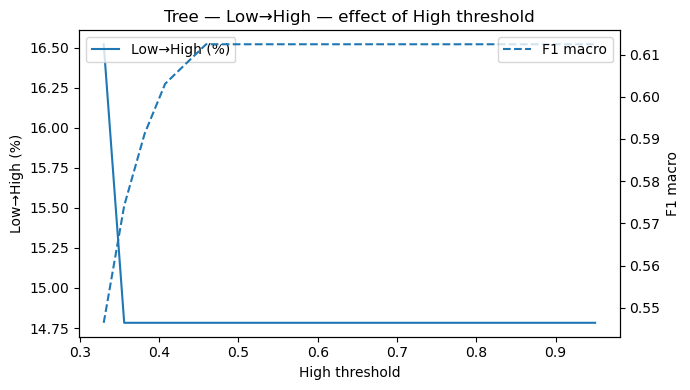

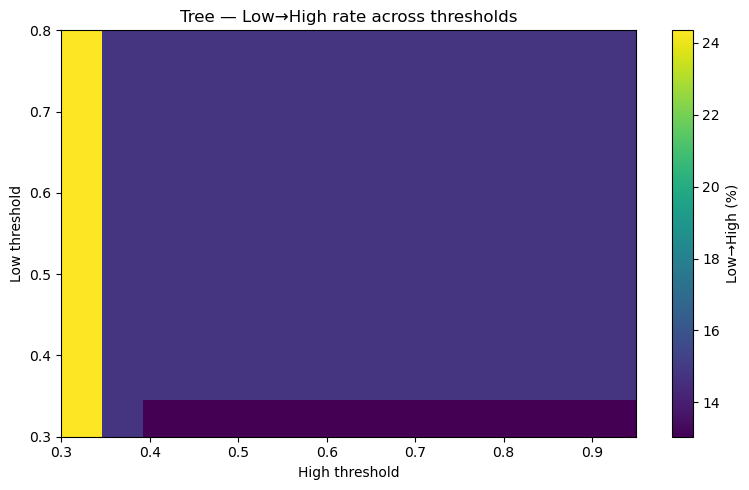

Best thresholds with F1 ≥ 0.592: t_low=0.30, t_high=0.45 → Low→High=13.0% | F1=0.597


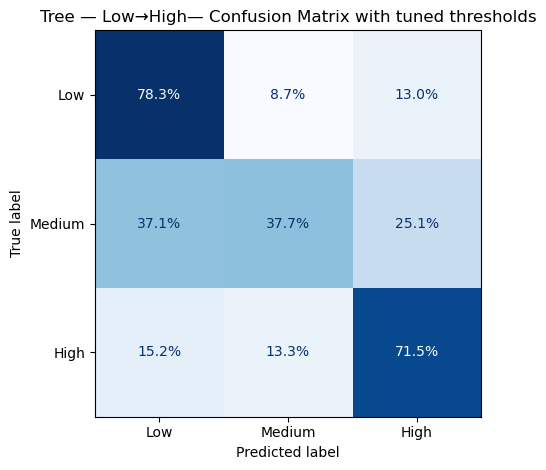


Confusion matrix (counts):


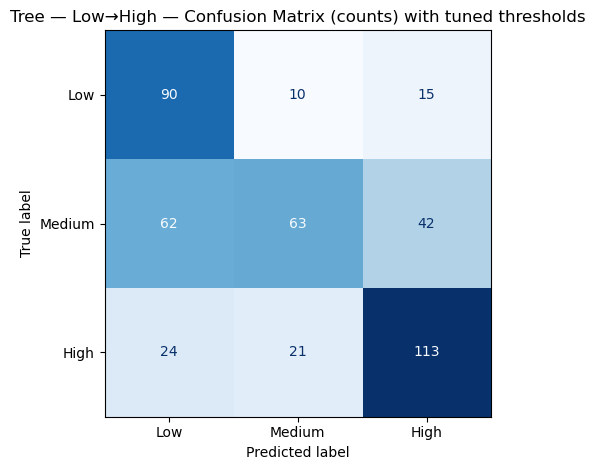


Accuracy: 0.6045454545454545
F1 (macro): 0.5967799039881618

Classification report:
              precision    recall  f1-score   support

         Low       0.51      0.78      0.62       115
      Medium       0.67      0.38      0.48       167
        High       0.66      0.72      0.69       158

    accuracy                           0.60       440
   macro avg       0.62      0.63      0.60       440
weighted avg       0.63      0.60      0.59       440



In [3]:
# --- Multiclass threshold tuning to reduce Low→High errors ---

def predict_with_cutoffs(proba, t_low=0.50, t_high=0.50):
    # Rule: if P(High) >= t_high → High; else if P(Low) >= t_low → Low; else → argmax
    y_pred = np.full(len(proba), 1)  # default Medium
    p_low, p_med, p_high = proba[:, 0], proba[:, 1], proba[:, 2]
    choose_high = p_high >= t_high
    choose_low  = (p_low >= t_low) & ~choose_high
    y_pred[choose_high] = 2
    y_pred[choose_low]  = 0
    remaining = ~(choose_high | choose_low)
    y_pred[remaining] = proba[remaining].argmax(axis=1)
    return y_pred

# Baseline (argmax)
y_argmax = proba.argmax(axis=1)
base_f1 = f1_score(y_test, y_argmax, average="macro")

# 1D sweep over High threshold (keep Low at 0.50)
ths = np.linspace(0.33, 0.95, 25)
low2high, f1s = [], []
for th in ths:
    y_pred = predict_with_cutoffs(proba, t_low=0.50, t_high=th)
    cm = confusion_matrix(y_test, y_pred, labels=[0,1,2], normalize="true")
    low2high.append(cm[0, 2])  # Top-right cell: true Low → predicted High
    f1s.append(f1_score(y_test, y_pred, average="macro"))

fig, ax1 = plt.subplots(figsize=(7,4))
ax1.plot(ths, np.array(low2high)*100, label="Low→High (%)")
ax1.set_xlabel("High threshold")
ax1.set_ylabel("Low→High (%)")
ax2 = ax1.twinx()
ax2.plot(ths, f1s, linestyle="--", label="F1 macro")
ax2.set_ylabel("F1 macro")
ax1.legend(loc="upper left"); ax2.legend(loc="upper right")
plt.title(f"Tree — Low→High — effect of High threshold")
plt.tight_layout(); plt.show()  # this shows the percentage of Low instances classified as High as we increase the threshold

# 2D grid over (t_low, t_high): heatmap of Low→High rate
tl_grid = np.linspace(0.30, 0.80, 11)
th_grid = np.linspace(0.30, 0.95, 14)
heat  = np.zeros((len(tl_grid), len(th_grid)))
f1grid = np.zeros_like(heat)

for i, tl in enumerate(tl_grid):
    for j, th in enumerate(th_grid):
        y_pred = predict_with_cutoffs(proba, t_low=tl, t_high=th)
        cm = confusion_matrix(y_test, y_pred, labels=[0,1,2], normalize="true")
        heat[i, j]  = cm[0, 2]  # Low→High
        f1grid[i, j] = f1_score(y_test, y_pred, average="macro")

plt.figure(figsize=(8,5))
im = plt.imshow(heat*100, origin="lower", aspect="auto",
                extent=[th_grid[0], th_grid[-1], tl_grid[0], tl_grid[-1]])
plt.colorbar(im, label="Low→High (%)")
plt.xlabel("High threshold"); plt.ylabel("Low threshold")
plt.title(f"Tree — Low→High rate across thresholds")
plt.tight_layout(); plt.show()

# Pick thresholds that minimize Low→High while keeping F1 close to baseline
f1_constraint = base_f1 - 0.02  # allow up to 0.02 drop in macro F1
best = None
for i, tl in enumerate(tl_grid):
    for j, th in enumerate(th_grid):
        if f1grid[i, j] >= f1_constraint:
            if best is None or heat[i, j] < best[0]:  #heat[i,j] contains the proportion of Low->High
                best = (heat[i, j], tl, th, f1grid[i, j])

if best:
    print(f"Best thresholds with F1 ≥ {f1_constraint:.3f}: "
          f"t_low={best[1]:.2f}, t_high={best[2]:.2f} → Low→High={best[0]*100:.1f}% | F1={best[3]:.3f}")
    y_best = predict_with_cutoffs(proba, t_low=best[1], t_high=best[2])
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_best, labels=[0,1,2], display_labels=["Low","Medium","High"],
        normalize="true", values_format=".1%", cmap="Blues", colorbar=False
    )
    plt.title(f"Tree — Low→High— Confusion Matrix with tuned thresholds")
    plt.tight_layout(); plt.show()

    # Confusion matrix with raw counts
    cm_counts = confusion_matrix(y_test, y_best, labels=[0,1,2])
    print("\nConfusion matrix (counts):")

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_best,
        labels=[0,1,2],
        display_labels=["Low","Medium","High"],
        normalize=None,            # raw counts
        values_format="d",
        cmap="Blues",
        colorbar=False,
    )
    plt.title("Tree — Low→High — Confusion Matrix (counts) with tuned thresholds")
    plt.tight_layout(); plt.show()

    # Accuracy & macro-F1
    acc = accuracy_score(y_test, y_best)
    f1m = f1_score(y_test, y_best, average="macro")
    print(f"\nAccuracy: {acc}")
    print(f"F1 (macro): {f1m}\n")

    # Classification report (with class names)
    print("Classification report:")
    print(classification_report(
        y_test, y_best,
        labels=[0,1,2],
        target_names=["Low","Medium","High"]
    ))
